<a href="https://colab.research.google.com/github/setiavikas/coffee-reviews-sentiment-analysis/blob/main/Coffee_Reviews_Sentiment_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
reviews = [
    "Excellent coffee and friendly staff!",
    "The coffee was cold and the service was slow.",
    "Nice ambience, but the food was expensive.",
    "Great cappuccino. I will visit again.",
    "Average coffee. Nothing special.",
    "Staff were rude and the table was dirty.",
    "Loved the sandwiches and peaceful atmosphere.",
    "The coffee was good, but seating was uncomfortable.",
    "Very good service and delicious cake!",
    "The shop was crowded. Overall, it was okay."
]

print("Total reviews:", len(reviews))
print("\nFirst review:", reviews[0])

Total reviews: 10

First review: Excellent coffee and friendly staff!


In [ ]:

from google.colab import files

files.download("coffee_review_analysis.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

print("Here are all the coffee reviews:\n")

for i, review in enumerate(reviews, start=1):
    print(f"{i}. {review}")


Here are all the coffee reviews:

1. Excellent coffee and friendly staff!
2. The coffee was cold and the service was slow.
3. Nice ambience, but the food was expensive.
4. Great cappuccino. I will visit again.
5. Average coffee. Nothing special.
6. Staff were rude and the table was dirty.
7. Loved the sandwiches and peaceful atmosphere.
8. The coffee was good, but seating was uncomfortable.
9. Very good service and delicious cake!
10. The shop was crowded. Overall, it was okay.


In [ ]:

print("Coffee review analysis")
print("-----------------------")
print("Total reviews:", len(results))
print()

for row in results:
    print(row["Review_ID"], "|", row["Sentiment"], "|", row["Review"])


Coffee review analysis
-----------------------
Total reviews: 10

1 | Positive | Excellent coffee and friendly staff!
2 | Negative | The coffee was cold and the service was slow.
3 | Mixed/Neutral | Nice ambience, but the food was expensive.
4 | Positive | Great cappuccino. I will visit again.
5 | Mixed/Neutral | Average coffee. Nothing special.
6 | Negative | Staff were rude and the table was dirty.
7 | Positive | Loved the sandwiches and peaceful atmosphere.
8 | Mixed/Neutral | The coffee was good, but seating was uncomfortable.
9 | Positive | Very good service and delicious cake!
10 | Negative | The shop was crowded. Overall, it was okay.


In [ ]:

import pandas as pd

df = pd.DataFrame(results)

print("Our coffee review dataset:")
display(df)

print("Dataset size:", df.shape)


Our coffee review dataset:


,Review_ID,Review,Positive_Matches,Negative_Matches,Sentiment
0,1,Excellent coffee and friendly staff!,2,0,Positive
1,2,The coffee was cold and the service was slow.,0,2,Negative
2,3,"Nice ambience, but the food was expensive.",1,1,Mixed/Neutral
3,4,Great cappuccino. I will visit again.,1,0,Positive
4,5,Average coffee. Nothing special.,0,0,Mixed/Neutral
5,6,Staff were rude and the table was dirty.,0,2,Negative
6,7,Loved the sandwiches and peaceful atmosphere.,2,0,Positive
7,8,"The coffee was good, but seating was uncomfort...",1,1,Mixed/Neutral
8,9,Very good service and delicious cake!,2,0,Positive
9,10,"The shop was crowded. Overall, it was okay.",0,1,Negative


Dataset size: (10, 5)


In [ ]:

negative_df = df[df["Sentiment"] == "Negative"]

print("Negative reviews:")
display(negative_df)

print("Number of negative reviews:", len(negative_df))


Negative reviews:


,Review_ID,Review,Positive_Matches,Negative_Matches,Sentiment
1,2,The coffee was cold and the service was slow.,0,2,Negative
5,6,Staff were rude and the table was dirty.,0,2,Negative
9,10,"The shop was crowded. Overall, it was okay.",0,1,Negative


Number of negative reviews: 3


In [ ]:

print("Sentiment distribution:")
print(df["Sentiment"].value_counts())

print("\nSentiment percentages:")
print((df["Sentiment"].value_counts(normalize=True) * 100).round(1))


Sentiment distribution:
Sentiment
Positive         4
Negative         3
Mixed/Neutral    3
Name: count, dtype: int64

Sentiment percentages:
Sentiment
Positive         40.0
Negative         30.0
Mixed/Neutral    30.0
Name: proportion, dtype: float64


In [ ]:

print("Reviews ranked by negative-word matches:")

ranked_reviews = df.sort_values(
    by="Negative_Matches",
    ascending=False
)

display(
    ranked_reviews[
        ["Review_ID", "Review", "Negative_Matches", "Sentiment"]
    ]
)


Reviews ranked by negative-word matches:


,Review_ID,Review,Negative_Matches,Sentiment
1,2,The coffee was cold and the service was slow.,2,Negative
5,6,Staff were rude and the table was dirty.,2,Negative
9,10,"The shop was crowded. Overall, it was okay.",1,Negative
2,3,"Nice ambience, but the food was expensive.",1,Mixed/Neutral
7,8,"The coffee was good, but seating was uncomfort...",1,Mixed/Neutral
0,1,Excellent coffee and friendly staff!,0,Positive
4,5,Average coffee. Nothing special.,0,Mixed/Neutral
3,4,Great cappuccino. I will visit again.,0,Positive
6,7,Loved the sandwiches and peaceful atmosphere.,0,Positive
8,9,Very good service and delicious cake!,0,Positive


In [ ]:

print("Missing values in each column:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nDataset shape:", df.shape)


Missing values in each column:
Review_ID           0
Review              0
Positive_Matches    0
Negative_Matches    0
Sentiment           0
dtype: int64

Duplicate rows: 0

Dataset shape: (10, 5)


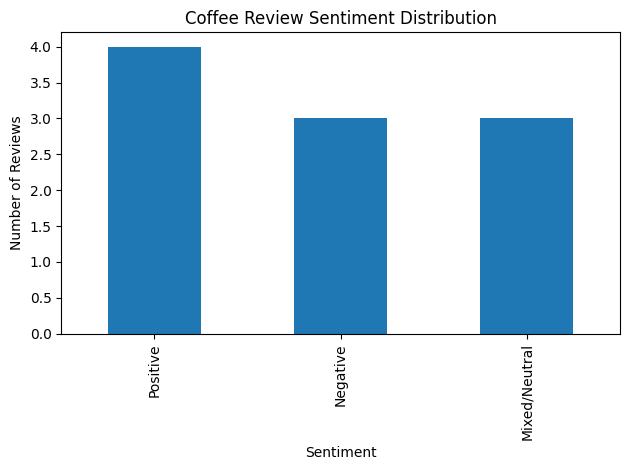

In [ ]:

sentiment_counts = df["Sentiment"].value_counts()

sentiment_counts.plot(
    kind="bar",
    title="Coffee Review Sentiment Distribution",
    xlabel="Sentiment",
    ylabel="Number of Reviews"
)

import matplotlib.pyplot as plt
plt.tight_layout()
plt.show()


In [ ]:
from collections import Counter
import re

all_words = []

for review in reviews:
    words = re.findall(r'\b[a-zA-Z]+\b', review.lower())
    all_words.extend(words)

word_counts = Counter(all_words)

print("Top 10 most common words:\n")
for word, count in word_counts.most_common(10):
    print(word, ":", count)

Top 10 most common words:

was : 8
the : 7
and : 5
coffee : 4
staff : 2
service : 2
but : 2
good : 2
excellent : 1
friendly : 1


In [ ]:
stop_words = {
    "the", "was", "and", "a", "an", "but", "it",
    "i", "will", "they", "is", "were", "to", "very",
    "my", "of", "in", "on", "with", "overall"
}

useful_words = []

for review in reviews:
    words = re.findall(r'\b[a-zA-Z]+\b', review.lower())

    for word in words:
        if word not in stop_words:
            useful_words.append(word)

useful_word_counts = Counter(useful_words)

print("Top 10 meaningful words:\n")
for word, count in useful_word_counts.most_common(10):
    print(word, ":", count)

Top 10 meaningful words:

coffee : 4
staff : 2
service : 2
good : 2
excellent : 1
friendly : 1
cold : 1
slow : 1
nice : 1
ambience : 1


In [ ]:
positive_keywords = ["good", "excellent", "friendly", "nice"]
negative_keywords = ["cold", "slow", "rude", "dirty"]

positive_found = []
negative_found = []

for review in reviews:
    words = set(review.lower().split())

    for word in positive_keywords:
        if word in words:
            positive_found.append(word)

    for word in negative_keywords:
        if word in words:
            negative_found.append(word)

print("Positive keyword counts:")
for word in positive_keywords:
    print(word, ":", positive_found.count(word))

print("\nNegative keyword counts:")
for word in negative_keywords:
    print(word, ":", negative_found.count(word))

Positive keyword counts:
good : 1
excellent : 1
friendly : 1
nice : 1

Negative keyword counts:
cold : 1
slow : 0
rude : 1
dirty : 0


In [ ]:
for review in reviews:
    if "slow" in review.lower() or "dirty" in review.lower():
        print(review)
        print(review.lower().split())
        print()

The coffee was cold and the service was slow.
['the', 'coffee', 'was', 'cold', 'and', 'the', 'service', 'was', 'slow.']

Staff were rude and the table was dirty.
['staff', 'were', 'rude', 'and', 'the', 'table', 'was', 'dirty.']



In [ ]:
import string

positive_found = []
negative_found = []

for review in reviews:
    words = set(
        word.strip(string.punctuation)
        for word in review.lower().split()
    )

    for word in positive_keywords:
        if word in words:
            positive_found.append(word)

    for word in negative_keywords:
        if word in words:
            negative_found.append(word)

print("Positive keyword counts:")
for word in positive_keywords:
    print(word, ":", positive_found.count(word))

print("\nNegative keyword counts:")
for word in negative_keywords:
    print(word, ":", negative_found.count(word))

Positive keyword counts:
good : 2
excellent : 1
friendly : 1
nice : 1

Negative keyword counts:
cold : 1
slow : 1
rude : 1
dirty : 1


In [ ]:
print("Total positive keyword matches:", len(positive_found))
print("Total negative keyword matches:", len(negative_found))

print("Difference:", len(positive_found) - len(negative_found))

Total positive keyword matches: 5
Total negative keyword matches: 4
Difference: 1


In [ ]:
replies = [
    # Review 1: Excellent coffee and friendly staff
    "It means a lot to know that both our coffee and our team's hospitality made your visit enjoyable. Creating a welcoming place with a great cup of coffee is exactly what we strive for. We'll share your kind feedback with our team to reinforce the service that made your visit special.",

    # Review 2: Cold coffee and slow service
    "A freshly served coffee and attentive service are essential to an enjoyable café visit. Your feedback highlights two areas where we need to be more consistent. We'll review our coffee-temperature checks and service wait times with the team.",

    # Review 3: Nice ambience but expensive food
    "We're pleased that our ambience made a good impression on you. We also recognize that customers want their food experience to feel worthwhile at the price they pay. We'll review our menu pricing and how clearly we communicate portion sizes and value.",

    # Review 4: Great cappuccino and intent to return
    "Knowing that you enjoyed our cappuccino enough to plan another visit is wonderful to hear. A well-made coffee should be something you look forward to, not just something you order. We'll continue checking our cappuccino preparation standards so your next cup lives up to this one.",

    # Review 5: Average coffee
    "Thank you for being candid about your experience, because honest feedback gives us a chance to improve. We want our coffee to leave you with a memorable impression rather than feeling ordinary. We'll review our brewing consistency and preparation process with our baristas.",

    # Review 6: Rude staff and dirty table
    "Every guest deserves a respectful welcome and a clean table, without having to ask for either. Your experience points to standards we need to reinforce across both hospitality and cleanliness. We'll introduce a table-cleanliness check between guests and review service expectations with our team.",

    # Review 7: Sandwiches and peaceful atmosphere
    "It's lovely to hear that our sandwiches and peaceful atmosphere came together to make your visit enjoyable. A café should offer both something delicious to eat and a place where people can slow down and relax. We'll maintain our food-preparation checks and keep the dining area calm and comfortable.",

    # Review 8: Good coffee but uncomfortable seating
    "We're glad the coffee worked well for you, and we appreciate you highlighting the discomfort caused by our seating. Comfort matters just as much as what's served in the cup when guests want to settle in and enjoy their time. We'll inspect our chairs and tables and identify any seating that needs adjustment.",

    # Review 9: Very good service and delicious cake
    "It's wonderful to know that our service and cake made such a positive impression on you. Feedback like yours celebrates the care that both our front-of-house and kitchen teams bring to a visit. We'll share your comments with both teams and maintain our cake-freshness checks before display.",

    # Review 10: Crowded shop and an okay overall experience
    "We appreciate you visiting us even when the shop felt crowded, and we understand how a busy space can affect the overall experience. We'd like your next visit to feel more relaxed and enjoyable from the moment you arrive. We'll review peak-hour table turnover and customer flow to help reduce congestion."
]

for i, (review, reply) in enumerate(zip(reviews, replies), start=1):
    print(f"Review {i}: {review}")
    print(f"Our reply: {reply}")
    print("-" * 80)

Review 1: Excellent coffee and friendly staff!
Our reply: It means a lot to know that both our coffee and our team's hospitality made your visit enjoyable. Creating a welcoming place with a great cup of coffee is exactly what we strive for. We'll share your kind feedback with our team to reinforce the service that made your visit special.
--------------------------------------------------------------------------------
Review 2: The coffee was cold and the service was slow.
Our reply: A freshly served coffee and attentive service are essential to an enjoyable café visit. Your feedback highlights two areas where we need to be more consistent. We'll review our coffee-temperature checks and service wait times with the team.
--------------------------------------------------------------------------------
Review 3: Nice ambience, but the food was expensive.
Our reply: We're pleased that our ambience made a good impression on you. We also recognize that customers want their food experience to

In [ ]:
df["Business_Reply"] = replies

display(df[["Review_ID", "Review", "Sentiment", "Business_Reply"]])

df.to_csv("coffee_reviews_with_replies.csv", index=False)

print("Saved successfully: coffee_reviews_with_replies.csv")
print("Total reviews with replies:", len(df))

,Review_ID,Review,Sentiment,Business_Reply
0,1,Excellent coffee and friendly staff!,Positive,It means a lot to know that both our coffee an...
1,2,The coffee was cold and the service was slow.,Negative,A freshly served coffee and attentive service ...
2,3,"Nice ambience, but the food was expensive.",Mixed/Neutral,We're pleased that our ambience made a good im...
3,4,Great cappuccino. I will visit again.,Positive,Knowing that you enjoyed our cappuccino enough...
4,5,Average coffee. Nothing special.,Mixed/Neutral,Thank you for being candid about your experien...
5,6,Staff were rude and the table was dirty.,Negative,Every guest deserves a respectful welcome and ...
6,7,Loved the sandwiches and peaceful atmosphere.,Positive,It's lovely to hear that our sandwiches and pe...
7,8,"The coffee was good, but seating was uncomfort...",Mixed/Neutral,"We're glad the coffee worked well for you, and..."
8,9,Very good service and delicious cake!,Positive,It's wonderful to know that our service and ca...
9,10,"The shop was crowded. Overall, it was okay.",Negative,We appreciate you visiting us even when the sh...


Saved successfully: coffee_reviews_with_replies.csv
Total reviews with replies: 10


In [ ]:
from google.colab import files
files.download("coffee_reviews_with_replies.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

positive_words = ["excellent", "amazing", "great", "friendly", "delicious", "love"]
negative_words = ["terrible", "bad", "poor", "stale", "bitter", "disappointing"]

positive_count = 0
negative_count = 0

for review in reviews:
    review_lower = review.lower()

    for word in positive_words:
        if word in review_lower:
            positive_count += 1

    for word in negative_words:
        if word in review_lower:
            negative_count += 1

print("Positive word matches:", positive_count)
print("Negative word matches:", negative_count)


Positive word matches: 5
Negative word matches: 0


In [ ]:

positive_words = ["excellent", "amazing", "great", "friendly", "delicious", "love"]
negative_words = ["terrible", "bad", "poor", "stale", "bitter", "disappointing"]

for i, review in enumerate(reviews, start=1):
    review_lower = review.lower()

    positive_found = [word for word in positive_words if word in review_lower]
    negative_found = [word for word in negative_words if word in review_lower]

    print(f"\nReview {i}: {review}")
    print("Positive words found:", positive_found)
    print("Negative words found:", negative_found)



Review 1: Excellent coffee and friendly staff!
Positive words found: ['excellent', 'friendly']
Negative words found: []

Review 2: The coffee was cold and the service was slow.
Positive words found: []
Negative words found: []

Review 3: Nice ambience, but the food was expensive.
Positive words found: []
Negative words found: []

Review 4: Great cappuccino. I will visit again.
Positive words found: ['great']
Negative words found: []

Review 5: Average coffee. Nothing special.
Positive words found: []
Negative words found: []

Review 6: Staff were rude and the table was dirty.
Positive words found: []
Negative words found: []

Review 7: Loved the sandwiches and peaceful atmosphere.
Positive words found: ['love']
Negative words found: []

Review 8: The coffee was good, but seating was uncomfortable.
Positive words found: []
Negative words found: []

Review 9: Very good service and delicious cake!
Positive words found: ['delicious']
Negative words found: []

Review 10: The shop was crowd

In [ ]:

positive_words = [
    "excellent", "amazing", "great", "friendly",
    "delicious", "love", "loved", "nice",
    "good", "perfect", "recommend"
]

negative_words = [
    "terrible", "bad", "poor", "stale", "bitter",
    "disappointing", "cold", "slow", "expensive",
    "rude", "dirty", "uncomfortable", "crowded"
]

for i, review in enumerate(reviews, start=1):
    review_lower = review.lower()

    positive_found = [word for word in positive_words if word in review_lower]
    negative_found = [word for word in negative_words if word in review_lower]

    print(f"\nReview {i}: {review}")
    print("Positive words found:", positive_found)
    print("Negative words found:", negative_found)



Review 1: Excellent coffee and friendly staff!
Positive words found: ['excellent', 'friendly']
Negative words found: []

Review 2: The coffee was cold and the service was slow.
Positive words found: []
Negative words found: ['cold', 'slow']

Review 3: Nice ambience, but the food was expensive.
Positive words found: ['nice']
Negative words found: ['expensive']

Review 4: Great cappuccino. I will visit again.
Positive words found: ['great']
Negative words found: []

Review 5: Average coffee. Nothing special.
Positive words found: []
Negative words found: []

Review 6: Staff were rude and the table was dirty.
Positive words found: []
Negative words found: ['rude', 'dirty']

Review 7: Loved the sandwiches and peaceful atmosphere.
Positive words found: ['love', 'loved']
Negative words found: []

Review 8: The coffee was good, but seating was uncomfortable.
Positive words found: ['good']
Negative words found: ['uncomfortable']

Review 9: Very good service and delicious cake!
Positive words 

In [ ]:

positive_words = [
    "excellent", "amazing", "great", "friendly",
    "delicious", "love", "loved", "nice",
    "good", "perfect", "recommend"
]

negative_words = [
    "terrible", "bad", "poor", "stale", "bitter",
    "disappointing", "cold", "slow", "expensive",
    "rude", "dirty", "uncomfortable", "crowded"
]

for i, review in enumerate(reviews, start=1):
    review_lower = review.lower()

    positive_count = sum(word in review_lower for word in positive_words)
    negative_count = sum(word in review_lower for word in negative_words)

    if positive_count > negative_count:
        sentiment = "Positive"
    elif negative_count > positive_count:
        sentiment = "Negative"
    else:
        sentiment = "Mixed/Neutral"

    print(f"Review {i}: {sentiment} | {review}")


Review 1: Positive | Excellent coffee and friendly staff!
Review 2: Negative | The coffee was cold and the service was slow.
Review 3: Mixed/Neutral | Nice ambience, but the food was expensive.
Review 4: Positive | Great cappuccino. I will visit again.
Review 5: Mixed/Neutral | Average coffee. Nothing special.
Review 6: Negative | Staff were rude and the table was dirty.
Review 7: Positive | Loved the sandwiches and peaceful atmosphere.
Review 8: Mixed/Neutral | The coffee was good, but seating was uncomfortable.
Review 9: Positive | Very good service and delicious cake!
Review 10: Negative | The shop was crowded. Overall, it was okay.


In [ ]:

sentiment_counts = {
    "Positive": 0,
    "Negative": 0,
    "Mixed/Neutral": 0
}

for review in reviews:
    review_lower = review.lower()

    positive_count = sum(word in review_lower for word in positive_words)
    negative_count = sum(word in review_lower for word in negative_words)

    if positive_count > negative_count:
        sentiment = "Positive"
    elif negative_count > positive_count:
        sentiment = "Negative"
    else:
        sentiment = "Mixed/Neutral"

    sentiment_counts[sentiment] += 1

print("COFFEE REVIEW SUMMARY")
print("---------------------")

for sentiment, count in sentiment_counts.items():
    print(f"{sentiment}: {count}")

print("Total reviews:", len(reviews))


COFFEE REVIEW SUMMARY
---------------------
Positive: 4
Negative: 3
Mixed/Neutral: 3
Total reviews: 10


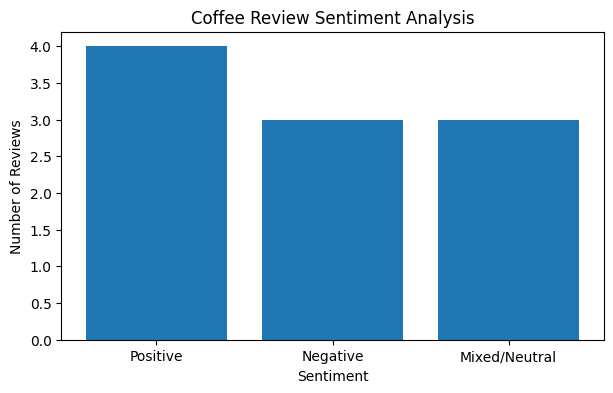

In [ ]:

import matplotlib.pyplot as plt

labels = list(sentiment_counts.keys())
counts = list(sentiment_counts.values())

plt.figure(figsize=(7, 4))
plt.bar(labels, counts)

plt.title("Coffee Review Sentiment Analysis")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")

plt.show()


In [ ]:

total_reviews = len(reviews)

print("COFFEE REVIEW PERCENTAGES")
print("-------------------------")

for sentiment, count in sentiment_counts.items():
    percentage = (count / total_reviews) * 100
    print(f"{sentiment}: {percentage:.1f}%")

print(f"Total reviews analyzed: {total_reviews}")


COFFEE REVIEW PERCENTAGES
-------------------------
Positive: 40.0%
Negative: 30.0%
Mixed/Neutral: 30.0%
Total reviews analyzed: 10


In [ ]:

print("CUSTOMER REVIEWS NEEDING ATTENTION")
print("-----------------------------------")

for i, review in enumerate(reviews, start=1):
    review_lower = review.lower()

    positive_count = sum(word in review_lower for word in positive_words)
    negative_count = sum(word in review_lower for word in negative_words)

    if negative_count > positive_count:
        print(f"\nReview {i}: {review}")


CUSTOMER REVIEWS NEEDING ATTENTION
-----------------------------------

Review 2: The coffee was cold and the service was slow.

Review 6: Staff were rude and the table was dirty.

Review 10: The shop was crowded. Overall, it was okay.


In [ ]:

total_reviews = len(reviews)
negative_reviews = 0

for review in reviews:
    review_lower = review.lower()

    positive_count = sum(word in review_lower for word in positive_words)
    negative_count = sum(word in review_lower for word in negative_words)

    if negative_count > positive_count:
        negative_reviews += 1

negative_percentage = (negative_reviews / total_reviews) * 100

print("CUSTOMER FEEDBACK ALERT")
print("-----------------------")
print("Total reviews:", total_reviews)
print("Negative reviews:", negative_reviews)
print(f"Negative review percentage: {negative_percentage:.1f}%")

if negative_percentage >= 30:
    print("Attention: Review the negative feedback.")
else:
    print("Continue monitoring customer feedback.")


CUSTOMER FEEDBACK ALERT
-----------------------
Total reviews: 10
Negative reviews: 3
Negative review percentage: 30.0%
Attention: Review the negative feedback.


In [ ]:

import pandas as pd

results = []

for i, review in enumerate(reviews, start=1):
    review_lower = review.lower()

    positive_count = sum(word in review_lower for word in positive_words)
    negative_count = sum(word in review_lower for word in negative_words)

    if positive_count > negative_count:
        sentiment = "Positive"
    elif negative_count > positive_count:
        sentiment = "Negative"
    else:
        sentiment = "Mixed/Neutral"

    results.append({
        "Review_ID": i,
        "Review": review,
        "Positive_Matches": positive_count,
        "Negative_Matches": negative_count,
        "Sentiment": sentiment
    })

df = pd.DataFrame(results)

df.to_csv("coffee_review_analysis.csv", index=False)

print("CSV file created successfully!")
print(df.head())


CSV file created successfully!
   Review_ID                                         Review  Positive_Matches  \
0          1           Excellent coffee and friendly staff!                 2   
1          2  The coffee was cold and the service was slow.                 0   
2          3     Nice ambience, but the food was expensive.                 1   
3          4          Great cappuccino. I will visit again.                 1   
4          5               Average coffee. Nothing special.                 0   

   Negative_Matches      Sentiment  
0                 0       Positive  
1                 2       Negative  
2                 1  Mixed/Neutral  
3                 0       Positive  
4                 0  Mixed/Neutral  


In [ ]:
import pandas as pd

df = pd.DataFrame({
    "Review_ID": range(1, len(reviews) + 1),
    "Customer_Review": reviews
})

display(df)

,Review_ID,Customer_Review
0,1,Excellent coffee and friendly staff!
1,2,The coffee was cold and the service was slow.
2,3,"Nice ambience, but the food was expensive."
3,4,Great cappuccino. I will visit again.
4,5,Average coffee. Nothing special.
5,6,Staff were rude and the table was dirty.
6,7,Loved the sandwiches and peaceful atmosphere.
7,8,"The coffee was good, but seating was uncomfort..."
8,9,Very good service and delicious cake!
9,10,"The shop was crowded. Overall, it was okay."


In [ ]:
def classify_review(review):
    positive_words = [
        "excellent", "friendly", "great", "loved",
        "delicious", "good", "peaceful", "visit again"
    ]

    negative_words = [
        "cold", "slow", "expensive", "rude",
        "dirty", "uncomfortable", "crowded"
    ]

    text = review.lower()
    positive = sum(word in text for word in positive_words)
    negative = sum(word in text for word in negative_words)

    if positive > negative:
        return "Positive"
    elif negative > positive:
        return "Negative"
    else:
        return "Neutral"

df["Sentiment"] = df["Customer_Review"].apply(classify_review)

display(df)

,Review_ID,Customer_Review,Sentiment
0,1,Excellent coffee and friendly staff!,Positive
1,2,The coffee was cold and the service was slow.,Negative
2,3,"Nice ambience, but the food was expensive.",Negative
3,4,Great cappuccino. I will visit again.,Positive
4,5,Average coffee. Nothing special.,Neutral
5,6,Staff were rude and the table was dirty.,Negative
6,7,Loved the sandwiches and peaceful atmosphere.,Positive
7,8,"The coffee was good, but seating was uncomfort...",Neutral
8,9,Very good service and delicious cake!,Positive
9,10,"The shop was crowded. Overall, it was okay.",Negative
